# Data Analysis — The Data Scientist Career Path: Pay, Skills and Personality

**Analytics objective.** The four datasets cover three stages of a data scientist's career:

| Stage | Dataset | Question |
|---|---|---|
| **Entering the market** | Analytics Jobs, DataScience Jobs | *What decides how much a data job pays: role, experience, city, company or skills?* |
| **Growing as a junior** | JDS Skill Traits | *Which technical skills earn a junior data scientist a high salary hike?* |
| **Succeeding as a senior** | SDS Personality Traits | *Which personality traits separate successful senior, customer-facing data scientists?* |

The goal is an **evidence-based career roadmap** for job seekers, universities/trainers and HR teams.

**Inputs.** This notebook reads the cleaned files written by `data_exploration.ipynb` (`cleaned/*.csv`). Run that notebook first.

**Methods used**

| Section | Technique |
|---|---|
| 1 | Kruskal-Wallis and Spearman tests; OLS regression on log-salary (premium per title / per year of experience) |
| 1 | Company segmentation: hiring volume vs pay quadrants |
| 2 | Chi-square test + Cramér's V; skill premium odds ratios with Bonferroni correction |
| 2 | Multi-class salary-band prediction: Logistic Regression, Random Forest, Gradient Boosting; permutation importance |
| 3 | Mann-Whitney U + effect size; Logistic regression odds ratios; cross-validated classifiers; decision-tree rules; what-if simulation |
| 4 | The same for personality, plus K-Means personas |
| 5 | Synthesis → career roadmap and stakeholder implications |

## 0. Setup and load cleaned data

In [1]:
import warnings, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, roc_auc_score
from sklearn.inspection import permutation_importance
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
warnings.filterwarnings('ignore')

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50); pd.set_option('display.max_colwidth', 60)
RNG = 42

BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e1e0d9'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': MUTED, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 10,
    'legend.frameon': False, 'figure.dpi': 110,
})
SEQ = LinearSegmentedColormap.from_list('seq', ['#f4f8fd', '#9ec5f4', '#2a78d6', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#2a78d6', '#f0efec', '#eb6834'])

def hbar(series, title, xlabel, color=BLUE, fmt='{:,.0f}', ax=None):
    s = series.sort_values()
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 0.32 * len(s) + 1))
    ax.barh(s.index.astype(str), s.values, color=color, height=0.7)
    ax.grid(axis='y', visible=False)
    for i, v in enumerate(s.values):
        ax.text(v, i, ' ' + fmt.format(v), va='center', fontsize=8, color=MUTED)
    ax.set_title(title); ax.set_xlabel(xlabel)
    return ax

def place_labels(ax, xs, ys, names, fontsize=8):
    """Greedy direct labelling: try a few offsets per point and keep the first that overlaps no earlier label."""
    fig = ax.figure; fig.canvas.draw(); r = fig.canvas.get_renderer(); placed = []
    offsets = [(5, 3, 'left'), (5, -10, 'left'), (-5, 3, 'right'), (-5, -10, 'right'), (5, 12, 'left'), (5, -19, 'left')]
    for x, y, n in zip(xs, ys, names):
        for dx, dy, ha in offsets:
            t = ax.annotate(n, (x, y), xytext=(dx, dy), textcoords='offset points', fontsize=fontsize, color=INK, ha=ha)
            bb = t.get_window_extent(r).expanded(1.05, 1.15)
            if not any(bb.overlaps(p) for p in placed):
                placed.append(bb); break
            t.remove()

def forest(table, title, xlabel):
    """Odds-ratio forest plot: dot = OR, line = 95% CI, log x-axis, reference line at 1."""
    t = table.sort_values('odds_ratio')
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(t) + 1.2))
    y = np.arange(len(t))
    sig = t['p_value'] < 0.05
    ax.hlines(y, t['ci_low'], t['ci_high'], color=MUTED, lw=2)
    ax.scatter(t['odds_ratio'], y, s=70, color=np.where(sig, BLUE, '#c3c2b7'), zorder=3, edgecolor='#fcfcfb', linewidth=1.5)
    ax.axvline(1, color=INK, lw=1, ls='--')
    ax.set_xscale('log'); ax.set_yticks(y, t.index); ax.grid(axis='y', visible=False)
    from matplotlib.ticker import FuncFormatter, LogLocator
    ax.xaxis.set_major_locator(LogLocator(subs=(1, 2, 5)))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: ''))
    for yi, (o, p) in enumerate(zip(t['odds_ratio'], t['p_value'])):
        ax.text(t['ci_high'].iloc[yi] * 1.08, yi, f'OR {o:.2f}  (p={p:.3f})', va='center', fontsize=8, color=MUTED)
    ax.set_title(title); ax.set_xlabel(xlabel + '   (blue = significant at 5%, grey = not)')
    return ax

a   = pd.read_csv('cleaned/analytics_jobs_clean.csv')
d   = pd.read_csv('cleaned/ds_jobs_clean.csv')
jds = pd.read_csv('cleaned/jds_clean.csv')
sds = pd.read_csv('cleaned/sds_clean.csv')
BANDS = ['0to3', '3to6', '6to10', '10to15', '15to25', '25to50']
a['band_idx'] = a['salary'].map({b: i for i, b in enumerate(BANDS)})
a['cities'] = a['cities'].str.split('|')
for n, df in [('analytics', a), ('ds', d), ('jds', jds), ('sds', sds)]:
    print(f'{n:10s}', df.shape)

analytics  (14840, 19)
ds         (1602, 11)
jds        (139, 8)
sds        (161, 8)


## 1. What decides pay in the market? (DataScience Jobs)

### 1.1 Is pay really different across job titles, and does experience matter?
- **H0 (Kruskal-Wallis):** all 10 job titles have the same salary distribution. This test is non-parametric because salary is skewed.
- **H0 (Spearman):** there is no monotonic link between minimum experience and salary.

In [2]:
groups = [g['avg_salary_L'].values for _, g in d.groupby('job_title')]
H, p = stats.kruskal(*groups)
eps2 = (H - len(groups) + 1) / (len(d) - len(groups))          # epsilon-squared effect size
print(f'Kruskal-Wallis across job titles: H = {H:.1f}, p = {p:.2e}, effect size ε² = {eps2:.2f}')

rho, p2 = stats.spearmanr(d['min_experience'], d['avg_salary_L'])
print(f'Spearman experience vs salary:    rho = {rho:.2f}, p = {p2:.2e}')

# Is the experience effect still there *within* a title? (rules out "senior titles just need more years")
within = d.groupby('job_title').apply(lambda g: pd.Series(stats.spearmanr(g['min_experience'], g['avg_salary_L']), index=['rho', 'p']))
within.round(3).sort_values('rho', ascending=False)

Kruskal-Wallis across job titles: H = 833.4, p = 1.39e-173, effect size ε² = 0.52
Spearman experience vs salary:    rho = 0.63, p = 2.91e-180


,rho,p
job_title,,
Senior Business Analyst,0.592,0.000
Data Engineer,0.569,0.000
Business Analyst,0.521,0.000
Senior Data Engineer,0.460,0.000
Data Analyst,0.396,0.000
Machine Learning Engineer,0.384,0.003
Data Scientist,0.349,0.000
Senior Data Scientist,0.342,0.000
Data Architect,0.296,0.037


### 1.2 Regression: how much is each title and each year of experience worth?
The model is `log(avg_salary) ~ min_experience + job_title + big_hirer`. On a log scale, each coefficient converts to a **percentage premium**: `exp(b) − 1`.
`big_hirer` marks the 10 companies with the most openings. *Data Analyst* is the reference title.

In [3]:
top_hirers = d.groupby('company_name')['num_of_jobs'].sum().nlargest(10).index
d['big_hirer'] = d['company_name'].isin(top_hirers).astype(int)
d['log_salary'] = np.log(d['avg_salary_L'])

ols = smf.ols("log_salary ~ min_experience + C(job_title, Treatment('Data Analyst')) + big_hirer", data=d).fit(cov_type='HC3')
print(f'R² = {ols.rsquared:.3f}   adj. R² = {ols.rsquared_adj:.3f}   n = {int(ols.nobs)}   (robust HC3 standard errors)')

coef = pd.DataFrame({'b': ols.params, 'lo': ols.conf_int()[0], 'hi': ols.conf_int()[1], 'p': ols.pvalues}).drop('Intercept')
coef.index = [re.sub(r"C\(job_title.*\)\[T\.(.*)\]", r'\1', i) for i in coef.index]
prem = (np.exp(coef[['b', 'lo', 'hi']]) - 1) * 100
prem['p'] = coef['p']
prem.columns = ['premium_%', 'ci_low_%', 'ci_high_%', 'p_value']
prem.round(3)

R² = 0.583   adj. R² = 0.580   n = 1602   (robust HC3 standard errors)


,premium_%,ci_low_%,ci_high_%,p_value
Business Analyst,52.472,39.350,66.830,0.0
Data Architect,75.749,47.564,109.316,0.0
Data Engineer,97.936,79.765,117.945,0.0
Data Scientist,133.645,113.378,155.836,0.0
Machine Learning Engineer,63.917,42.159,89.005,0.0
Senior Business Analyst,73.542,56.991,91.838,0.0
Senior Data Analyst,35.834,22.191,51.000,0.0
Senior Data Engineer,134.116,111.369,159.312,0.0
Senior Data Scientist,197.158,169.447,227.718,0.0
min_experience,11.947,10.399,13.517,0.0


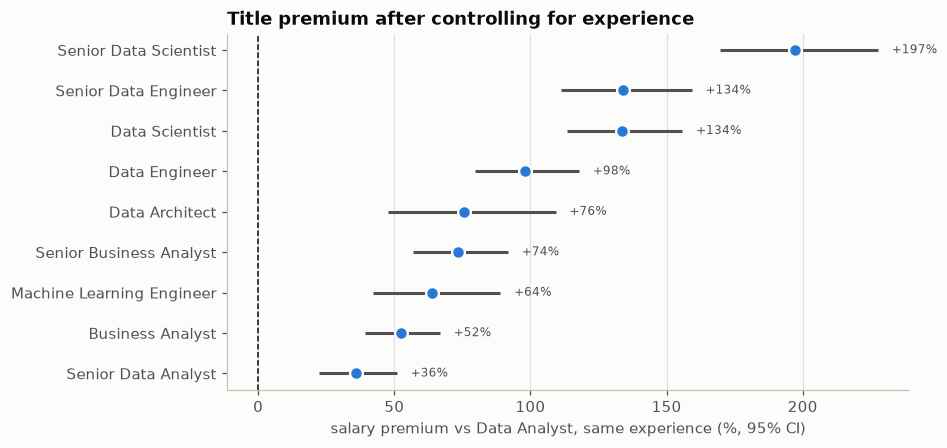

Each extra year of required experience: +11.9% salary (95% CI 10.4 to 13.5)
Working for a top-10 volume hirer:      -11.4% (p = 0.000)


In [4]:
t = prem.drop(['min_experience', 'big_hirer']).sort_values('premium_%')
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(t))
ax.hlines(y, t['ci_low_%'], t['ci_high_%'], color=MUTED, lw=2)
ax.scatter(t['premium_%'], y, s=70, color=BLUE, zorder=3, edgecolor='#fcfcfb', linewidth=1.5)
ax.axvline(0, color=INK, lw=1, ls='--')
ax.set_yticks(y, t.index); ax.grid(axis='y', visible=False)
for yi, v in enumerate(t['premium_%']):
    ax.text(t['ci_high_%'].iloc[yi] + 5, yi, f'+{v:.0f}%', va='center', fontsize=8, color=MUTED)
ax.set_xlabel('salary premium vs Data Analyst, same experience (%, 95% CI)')
ax.set_title('Title premium after controlling for experience')
plt.show()
e, bh = prem.loc['min_experience'], prem.loc['big_hirer']
print(f"Each extra year of required experience: +{e['premium_%']:.1f}% salary (95% CI {e['ci_low_%']:.1f} to {e['ci_high_%']:.1f})")
print(f"Working for a top-10 volume hirer:      {bh['premium_%']:+.1f}% (p = {bh['p_value']:.3f})")

**Interpretation.** Title, experience and employer type together explain **58%** of the variation in log-salary.
- At the *same* experience, a **Data Scientist earns about 2.3× a Data Analyst** (+134%), and a **Senior Data Scientist about 3×** (+197%).
- Data Architect's premium shrinks to +76% once experience is controlled for. Its high raw pay comes mostly from the 10+ years it requires.
- **Each year of required experience adds about 12%** to salary. The effect holds inside every title (Spearman rho 0.29–0.59, all p < 0.05).
- The **top-10 volume hirers pay about 11% less** for the same title and experience.

### 1.3 Company segmentation: who hires vs who pays
Companies are placed on two axes: total openings (hiring volume) and median salary. The median lines split them into four segments.

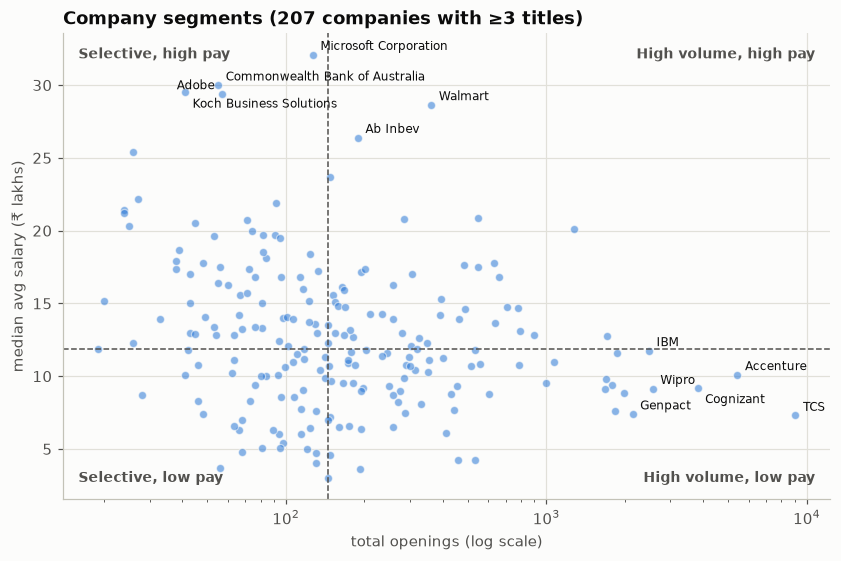

,companies,share_of_openings,median_salary
segment,,,
"High volume, high pay",44,22.5,14.7
"High volume, low pay",61,67.2,9.4
"Selective, high pay",62,5.6,16.6
"Selective, low pay",40,4.6,8.4


In [5]:
comp = d.groupby('company_name').agg(openings=('num_of_jobs', 'sum'), median_salary=('avg_salary_L', 'median'), titles=('job_title', 'nunique'))
comp = comp[comp['titles'] >= 3]                                   # enough roles to judge a company
mx, my = comp['openings'].median(), comp['median_salary'].median()
comp['segment'] = np.select(
    [(comp.openings >= mx) & (comp.median_salary >= my), (comp.openings >= mx) & (comp.median_salary < my),
     (comp.openings < mx) & (comp.median_salary >= my)],
    ['High volume, high pay', 'High volume, low pay', 'Selective, high pay'], 'Selective, low pay')

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(comp['openings'], comp['median_salary'], s=28, color=BLUE, alpha=0.55, edgecolor='#fcfcfb', linewidth=0.8)
ax.set_xscale('log'); ax.axvline(mx, color=MUTED, ls='--', lw=1); ax.axhline(my, color=MUTED, ls='--', lw=1)
label = pd.concat([comp.nlargest(6, 'openings'), comp.nlargest(6, 'median_salary')]).drop_duplicates()
place_labels(ax, label['openings'], label['median_salary'], label.index)
for (x, y_, txt) in [(0.98, 0.97, 'High volume, high pay'), (0.98, 0.03, 'High volume, low pay'),
                     (0.02, 0.97, 'Selective, high pay'), (0.02, 0.03, 'Selective, low pay')]:
    ax.text(x, y_, txt, transform=ax.transAxes, ha='right' if x > 0.5 else 'left', va='top' if y_ > 0.5 else 'bottom',
            fontsize=9, color=MUTED, fontweight='bold')
ax.set_xlabel('total openings (log scale)'); ax.set_ylabel('median avg salary (₹ lakhs)')
ax.set_title(f'Company segments ({len(comp)} companies with ≥3 titles)')
plt.show()
comp.groupby('segment').agg(companies=('openings', 'size'), share_of_openings=('openings', 'sum'), median_salary=('median_salary', 'median')) \
    .assign(share_of_openings=lambda t: (t.share_of_openings / t.share_of_openings.sum() * 100).round(1)).round(1)

**Interpretation.** About **two-thirds of all openings (67%) come from "high volume, low pay" companies**, with a median of 9.4 L. "Selective, high pay" companies offer the best median pay (16.6 L) but only about 6% of openings.
A job seeker's realistic first job is most likely a volume hirer. The best-paid jobs are scarce and competitive.

## 2. Which roles, cities and skills earn more? (Analytics Jobs)
Salary in this file is an **ordinal band**, so we use rank-based and categorical tests and treat prediction as a classification problem.
We exclude the 10 rows flagged `exp_band_conflict` (10+ years of experience with pay under 3 L), which are likely data-entry errors.

In [6]:
a = a[~a['exp_band_conflict']].copy()
a['high_pay'] = (a['band_idx'] >= 4).astype(int)          # 15 L+ bands
print(f'rows used: {len(a):,} | share in 15 L+ bands: {a.high_pay.mean():.1%}')

def cramers_v(ct):
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum(); r, k = ct.shape
    return chi2, p, dof, np.sqrt(chi2 / (n * (min(r, k) - 1)))

top_city = a['primary_city'].value_counts().head(8).index
a['city8'] = a['primary_city'].where(a['primary_city'].isin(top_city), 'Other')
a['exp_bucket'] = pd.cut(a['exp_min'], [-1, 1, 3, 5, 8, 30], labels=['0-1', '2-3', '4-5', '6-8', '9+'])

rows = []
for col in ['exp_bucket', 'role_group', 'city8', 'is_fresher', 'junk_posting']:
    chi2, p, dof, v = cramers_v(pd.crosstab(a[col], a['salary']))
    rows.append({'factor': col, 'chi2': round(chi2), 'dof': dof, 'p_value': p, "cramers_v": round(v, 3)})
assoc = pd.DataFrame(rows).set_index('factor').sort_values('cramers_v', ascending=False)
assoc

rows used: 14,830 | share in 15 L+ bands: 26.1%


,chi2,dof,p_value,cramers_v
factor,,,,
exp_bucket,9501,20,0.000000e+00,0.400
junk_posting,536,5,1.062791e-113,0.190
is_fresher,412,5,8.925539e-87,0.167
city8,645,40,3.335783e-110,0.093
role_group,641,30,1.178966e-115,0.093


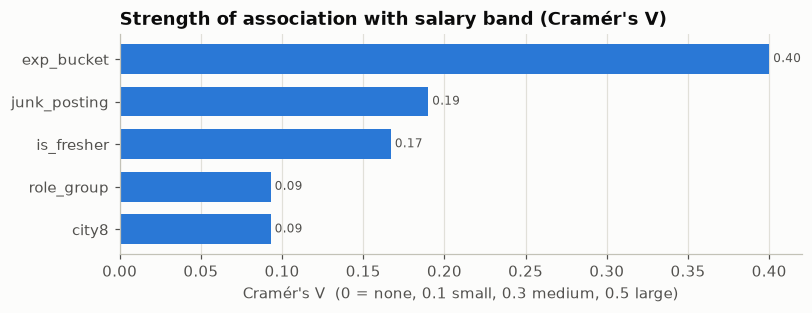

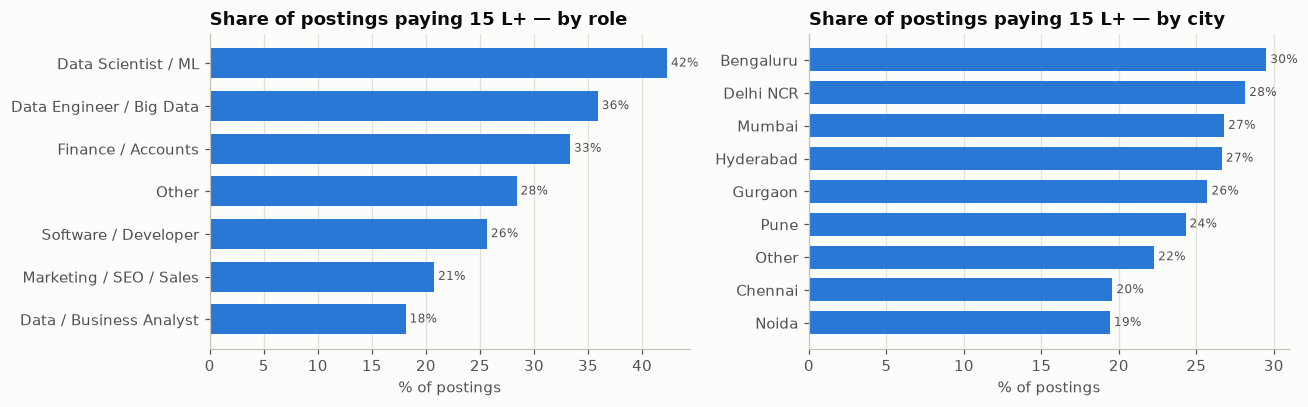

In [7]:
hbar(assoc['cramers_v'], "Strength of association with salary band (Cramér's V)", "Cramér's V  (0 = none, 0.1 small, 0.3 medium, 0.5 large)", fmt='{:.2f}')
plt.show()
city_rate = a.groupby('city8')['high_pay'].mean().mul(100)
role_rate = a.groupby('role_group')['high_pay'].mean().mul(100)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
hbar(role_rate, 'Share of postings paying 15 L+ — by role', '% of postings', fmt='{:.0f}%', ax=axes[0])
hbar(city_rate, 'Share of postings paying 15 L+ — by city', '% of postings', fmt='{:.0f}%', ax=axes[1])
plt.tight_layout(); plt.show()

**Interpretation.** All five factors are significant (p < 0.001), but their strength differs widely.
**Experience has a large association with salary band (V = 0.40)**. The junk-posting and fresher flags are small to moderate (about 0.17–0.19). City and role group are only *small* (V ≈ 0.09).
Where the job is matters far less than how experienced the candidate is.

### 2.1 Skill premium: which skills are linked to 15 L+ pay?
For every skill that appears in at least 100 postings, we compare the high-pay rate of postings **with** vs **without** the skill.
The **odds ratio** > 1 means the skill is linked to higher pay. A chi-square p-value is Bonferroni-corrected for the many skills tested.

In [8]:
sk = (a['key_skills'].fillna('').str.replace('...', '', regex=False).str.lower().str.split(',')
        .apply(lambda L: sorted({s.strip() for s in L if s.strip()})))
vocab = sk.explode().value_counts()
vocab = vocab[vocab >= 100].index
print('skills tested:', len(vocab))

rows = []
for s in vocab:
    has = sk.apply(lambda L, s=s: s in L)
    ct = pd.crosstab(has, a['high_pay']).reindex(index=[False, True], columns=[0, 1], fill_value=0) + 0.5
    or_ = (ct.loc[True, 1] * ct.loc[False, 0]) / (ct.loc[True, 0] * ct.loc[False, 1])
    p = stats.chi2_contingency(ct)[1]
    rows.append({'skill': s, 'postings': int(has.sum()), 'high_pay_rate_%': a.loc[has, 'high_pay'].mean() * 100,
                 'odds_ratio': or_, 'p_bonf': min(p * len(vocab), 1)})
skill_prem = pd.DataFrame(rows).set_index('skill')
skill_prem['significant'] = skill_prem['p_bonf'] < 0.05
print('significant after Bonferroni:', int(skill_prem.significant.sum()), 'of', len(skill_prem))
pd.concat([skill_prem.nlargest(10, 'odds_ratio'), skill_prem.nsmallest(8, 'odds_ratio')]).round(3)

skills tested: 116


significant after Bonferroni: 42 of 116


,postings,high_pay_rate_%,odds_ratio,p_bonf,significant
skill,,,,,
credit risk,112,52.679,3.188,0.000,True
statistical modeling,124,47.581,2.601,0.000,True
software development,185,45.946,2.445,0.000,True
algorithms,190,45.789,2.430,0.000,True
c++,226,43.805,2.246,0.000,True
r,616,42.857,2.211,0.000,True
nlp,146,43.151,2.176,0.000,True
deep learning,147,42.857,2.150,0.000,True
product management,210,42.381,2.115,0.000,True


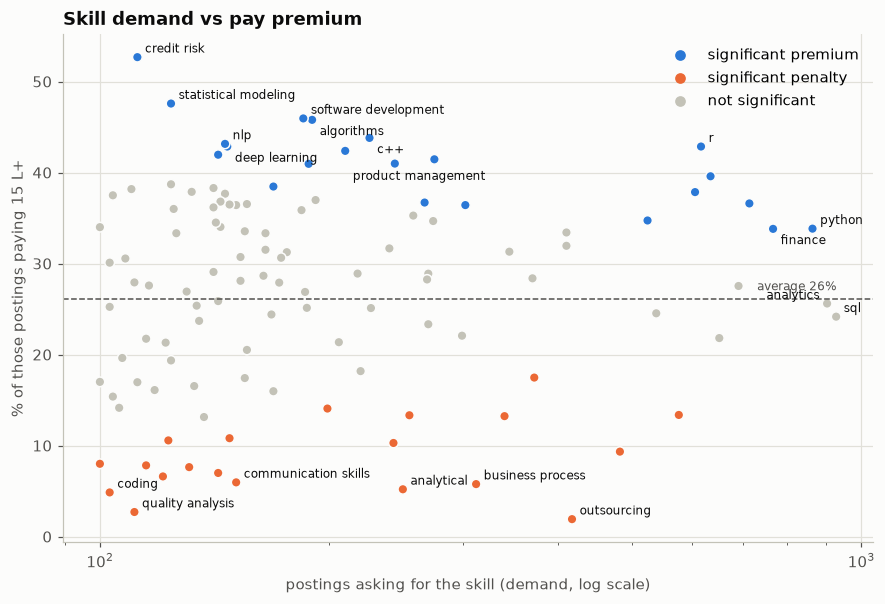

In [9]:
# Demand (how often a skill is asked for) vs premium (how much more likely it pays 15 L+)
sp = skill_prem
fig, ax = plt.subplots(figsize=(9.5, 6))
base = a['high_pay'].mean() * 100
c = np.where(~sp.significant, '#c3c2b7', np.where(sp['odds_ratio'] > 1, BLUE, ORANGE))
ax.scatter(sp['postings'], sp['high_pay_rate_%'], s=40, c=c, edgecolor='#fcfcfb', linewidth=1)
ax.set_xscale('log'); ax.axhline(base, color=MUTED, ls='--', lw=1)
ax.text(sp['postings'].max(), base + 1, f'average {base:.0f}%', ha='right', fontsize=8, color=MUTED)
lab = pd.concat([sp[sp.significant].nlargest(9, 'odds_ratio'), sp[sp.significant].nsmallest(6, 'odds_ratio'),
                 sp.nlargest(4, 'postings')]).drop_duplicates()
place_labels(ax, lab['postings'], lab['high_pay_rate_%'], lab.index)
ax.scatter([], [], c=BLUE, label='significant premium'); ax.scatter([], [], c=ORANGE, label='significant penalty')
ax.scatter([], [], c='#c3c2b7', label='not significant'); ax.legend(loc='upper right')
ax.set_xlabel('postings asking for the skill (demand, log scale)'); ax.set_ylabel('% of those postings paying 15 L+')
ax.set_title('Skill demand vs pay premium')
plt.show()

**Interpretation.** 42 of 116 common skills have a significant link with pay after Bonferroni correction.
- **Premium skills** (odds ratio about 2–3×): credit risk, statistical modelling, software development, algorithms, C++, R, NLP, deep learning, product management, financial modelling.
- **Penalty skills** (odds ratio about 0.06–0.2): outsourcing, BPO, quality analysis, business process, Google AdWords, and generic keywords such as "analytical", "coding" and "communication skills".
- Postings that list generic soft-skill keywords are usually entry-level or support roles. *Specific, technical* skills are what signal higher pay.

### 2.2 Can we predict a posting's salary band?
**Features:** experience (min, max, fresher flag), number of cities, primary city (top 8), role group, junk flag, and a multi-hot encoding of the 150 most common skills.
**Target:** 6 salary bands. Because the bands are ordered, we also report **within-one-band accuracy**, which counts a prediction as correct if it is at most one band away.
**Validation:** stratified 5-fold cross-validation, then a held-out 20% test set for the confusion matrix and feature importance.

In [10]:
top_sk =sk.explode().value_counts().head(150).index
S = pd.DataFrame({f'skill_{s}': sk.apply(lambda L, s=s: int(s in L)) for s in top_sk}, index=a.index)
X = pd.concat([a[['exp_min', 'exp_max', 'n_cities']].astype(float),
               a[['is_fresher', 'junk_posting']].astype(int),
               pd.get_dummies(a['city8'], prefix='city', dtype=int),
               pd.get_dummies(a['role_group'], prefix='role', dtype=int), S], axis=1)
y = a['band_idx'].values
print('feature matrix:', X.shape)

def within_one(y_true, y_pred): return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred)) <= 1)
from sklearn.metrics import make_scorer
scoring = {'accuracy': 'accuracy', 'macro_f1': 'f1_macro', 'within_one': make_scorer(within_one)}
models = {
    'Baseline (most frequent)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5)),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RNG),
    'Gradient Boosting': HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=RNG),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RNG)
res = {n: pd.DataFrame(cross_validate(m, X, y, cv=cv, scoring=scoring, n_jobs=1)).mean() for n, m in models.items()}
band_scores = pd.DataFrame(res).T[['test_accuracy', 'test_macro_f1', 'test_within_one']].round(3)
band_scores.columns = ['accuracy', 'macro_F1', 'within_one_band']
band_scores

feature matrix: (14830, 171)


,accuracy,macro_F1,within_one_band
Baseline (most frequent),0.236,0.064,0.624
Logistic Regression,0.414,0.386,0.829
Random Forest,0.393,0.358,0.830
Gradient Boosting,0.411,0.390,0.830


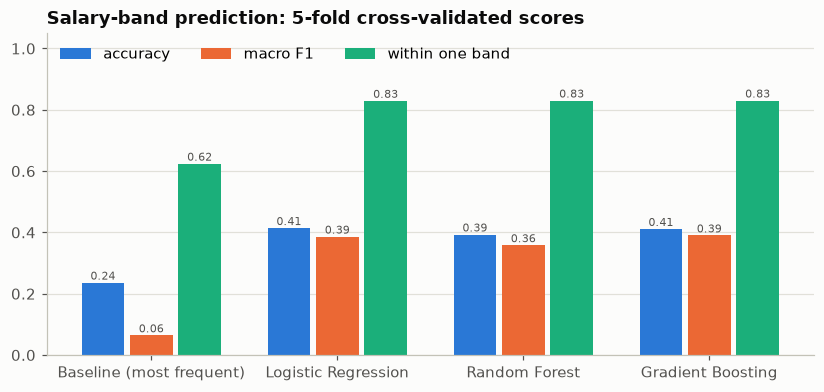

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(band_scores)); w = 0.26
for i, (col, colr) in enumerate(zip(band_scores.columns, [BLUE, ORANGE, AQUA])):
    ax.bar(x + (i - 1) * w, band_scores[col], w - 0.03, color=colr, label=col.replace('_', ' '))
    for xi, v in zip(x, band_scores[col]):
        ax.text(xi + (i - 1) * w, v + 0.01, f'{v:.2f}', ha='center', fontsize=7.5, color=MUTED)
ax.set_xticks(x, band_scores.index); ax.set_ylim(0, 1.05); ax.grid(axis='x', visible=False)
ax.set_title('Salary-band prediction: 5-fold cross-validated scores'); ax.legend(loc='upper left', ncol=3)
plt.show()

Best model: Logistic Regression | test accuracy 0.417 | within-one-band 0.837


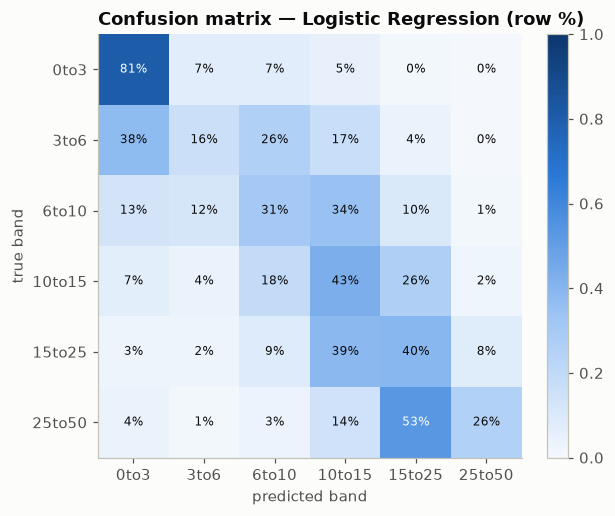

In [12]:
best_name = band_scores['accuracy'].drop('Baseline (most frequent)').idxmax()
best = models[best_name]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RNG)
best.fit(Xtr, ytr); pred = best.predict(Xte)
print(f'Best model: {best_name} | test accuracy {accuracy_score(yte, pred):.3f} | within-one-band {within_one(yte, pred):.3f}')

cm = confusion_matrix(yte, pred, normalize='true')
fig, ax = plt.subplots(figsize=(6, 5)); ax.grid(False)
im = ax.imshow(cm, cmap=SEQ, vmin=0, vmax=1)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f'{cm[i, j]:.0%}', ha='center', va='center', fontsize=8, color='white' if cm[i, j] > 0.5 else INK)
ax.set_xticks(range(6), BANDS); ax.set_yticks(range(6), BANDS)
ax.set_xlabel('predicted band'); ax.set_ylabel('true band'); ax.set_title(f'Confusion matrix — {best_name} (row %)')
plt.colorbar(im, ax=ax, fraction=0.046); plt.show()

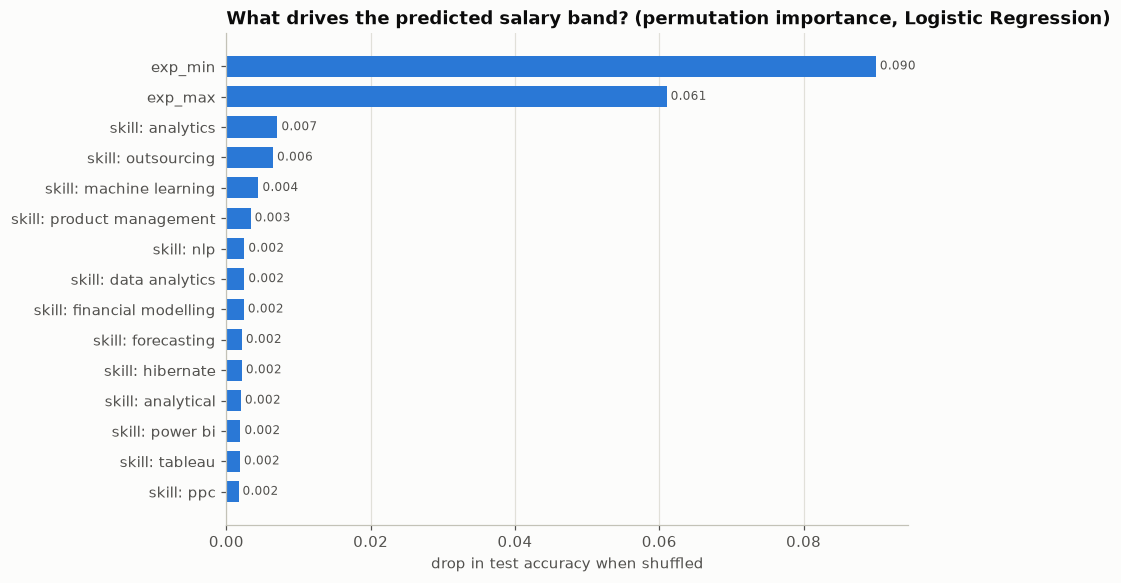

exp_min                       0.0900
exp_max                       0.0610
skill: analytics              0.0071
skill: outsourcing            0.0065
skill: machine learning       0.0045
skill: product management     0.0034
skill: nlp                    0.0025
skill: data analytics         0.0025
skill: financial modelling    0.0024
skill: forecasting            0.0022
skill: hibernate              0.0022
skill: analytical             0.0020
skill: power bi               0.0020
skill: tableau                0.0019
skill: ppc                    0.0017
dtype: float64

In [13]:
pi = permutation_importance(best, Xte, yte, n_repeats=5, random_state=RNG, n_jobs=1, scoring='accuracy')
imp = pd.Series(pi.importances_mean, index=X.columns)
# Group one-hot columns back to their parent factor so the ranking is readable
group = lambda c: ('city' if c.startswith('city_') else 'role group' if c.startswith('role_')
                   else c.replace('skill_', 'skill: ') if c.startswith('skill_') else c)
imp_g = imp.groupby(imp.index.map(group)).sum().sort_values(ascending=False)
hbar(imp_g.head(15), f'What drives the predicted salary band? (permutation importance, {best_name})', 'drop in test accuracy when shuffled', fmt='{:.3f}')
plt.show()
imp_g.head(15).round(4)

**Interpretation.** Exact-band accuracy is about **41%** against a 24% baseline. **Within-one-band accuracy is about 83%** against 62%. All three models perform similarly, so the limit comes from the data (truncated skills, banded salary) rather than the algorithm.
Permutation importance confirms that **experience dominates** prediction. Skills such as analytics, outsourcing, ML, product management and NLP refine the prediction.
Most errors are confusions with an *adjacent* band (see the confusion matrix), which is acceptable for a salary-guidance tool.

## 3. Junior data scientists: which skills earn a high salary hike? (JDS)

### 3.1 Statistical tests
Ratings are bounded (1–5) and skewed, so we use the **Mann-Whitney U** test. The effect size is the **rank-biserial correlation** *r*: 0.1 is small, 0.3 medium and 0.5 large. p-values are Bonferroni-corrected for 5 tests.

In [14]:
skill_cols = ['big_data_skills', 'maths_stats_skills', 'coding_skills', 'ai_and_ml_skills', 'dashboard_and_storytelling_skills']
trait_cols = ['neuroticism', 'extraversion', 'openness_to_experience', 'agreeableness', 'conscientiousness']

def mw_table(df, cols, target):
    rows = []
    for c in cols:
        x1, x0 = df.loc[df[target] == 1, c], df.loc[df[target] == 0, c]
        U, p = stats.mannwhitneyu(x1, x0, alternative='two-sided')
        rows.append({'feature': c, 'median_high': x1.median(), 'median_low': x0.median(),
                     'U': U, 'p_bonferroni': min(p * len(cols), 1), 'effect_r': 2 * U / (len(x1) * len(x0)) - 1})
    t = pd.DataFrame(rows).set_index('feature').sort_values('effect_r', ascending=False)
    t['verdict'] = np.where(t['p_bonferroni'] < 0.05, 'significant', 'not significant')
    return t.round(4)

mw_table(jds, skill_cols, 'hike_high')

,median_high,median_low,U,p_bonferroni,effect_r,verdict
feature,,,,,,
dashboard_and_storytelling_skills,5.0,3.85,3827.5,0.0000,0.5888,significant
maths_stats_skills,5.0,3.80,3735.5,0.0000,0.5506,significant
coding_skills,5.0,3.90,3585.0,0.0000,0.4882,significant
ai_and_ml_skills,5.0,4.60,3284.0,0.0004,0.3632,significant
big_data_skills,3.8,3.75,2701.0,1.0000,0.1212,not significant


### 3.2 Logistic regression: the odds of a high hike for each +1 point of skill
This model estimates each skill's effect *while holding the other skills fixed*. An odds ratio of 2 means each extra rating point doubles the odds of a high hike.

McFadden pseudo-R² = 0.499   LLR p-value = 3.61e-19   n = 139


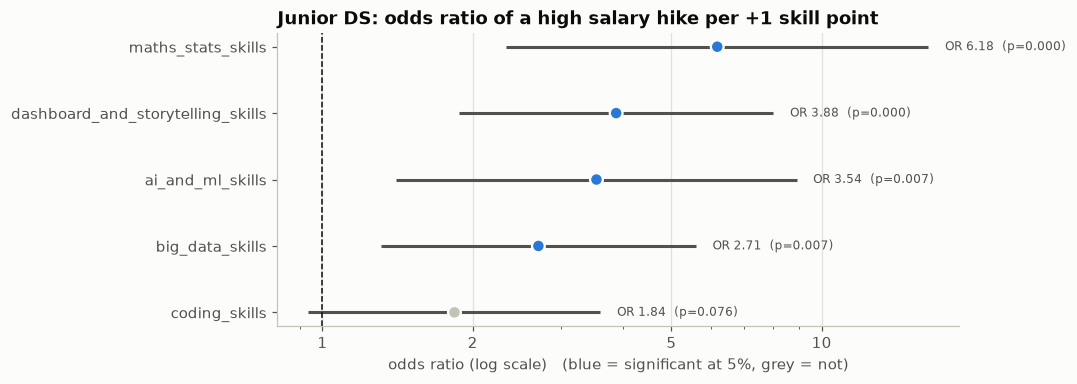

,odds_ratio,ci_low,ci_high,p_value
big_data_skills,2.708,1.310,5.599,0.007
maths_stats_skills,6.178,2.333,16.361,0.000
coding_skills,1.839,0.938,3.605,0.076
ai_and_ml_skills,3.539,1.407,8.904,0.007
dashboard_and_storytelling_skills,3.876,1.877,8.004,0.000


In [15]:
logit_j = smf.logit('hike_high ~ ' + ' + '.join(skill_cols), data=jds).fit(disp=0)
print(f'McFadden pseudo-R² = {logit_j.prsquared:.3f}   LLR p-value = {logit_j.llr_pvalue:.2e}   n = {int(logit_j.nobs)}')
or_j = pd.DataFrame({'odds_ratio': np.exp(logit_j.params), 'ci_low': np.exp(logit_j.conf_int()[0]),
                     'ci_high': np.exp(logit_j.conf_int()[1]), 'p_value': logit_j.pvalues}).drop('Intercept')
forest(or_j, 'Junior DS: odds ratio of a high salary hike per +1 skill point', 'odds ratio (log scale)')
plt.show()
or_j.round(3)

**Interpretation.**
- In the one-at-a-time tests (3.1), **dashboard/storytelling (r = 0.59)** and **maths/stats (r = 0.55)** have the largest effects. Coding and AI/ML are medium. **Big data is not significant on its own.**
- In the multivariable model, **maths/stats has the strongest independent effect: each +1 point multiplies the odds by about 6.2.** Storytelling (×3.9), AI/ML (×3.5) and big data (×2.7) follow. Coding is borderline (p = 0.08).
- Big data matters *only after the other skills are held constant*. This is a suppression effect: big data is slightly negatively correlated with maths/stats (r = −0.12). Big-data skill helps only on top of a strong maths and communication base.
- The model explains a lot (McFadden pseudo-R² = 0.50; values above 0.2 are considered a good fit).

### 3.3 Predictive models (repeated cross-validation)
The dataset is small (139 rows), so we use 5-fold cross-validation repeated 10 times and report the mean ± standard deviation.

In [16]:
from sklearn.model_selection import RepeatedStratifiedKFold
def compare_models(X, y):
    rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RNG)
    mods = {'Baseline': DummyClassifier(strategy='most_frequent'),
            'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
            'Decision Tree (depth 3)': DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=RNG),
            'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=RNG, n_jobs=-1)}
    out = {}
    for n, m in mods.items():
        r = cross_validate(m, X, y, cv=rcv, scoring=['accuracy', 'roc_auc', 'f1'])
        out[n] = {'accuracy': f"{r['test_accuracy'].mean():.3f} ± {r['test_accuracy'].std():.3f}",
                  'ROC_AUC': f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}",
                  'F1': f"{r['test_f1'].mean():.3f} ± {r['test_f1'].std():.3f}"}
    return pd.DataFrame(out).T

Xj, yj = jds[skill_cols], jds['hike_high']
compare_models(Xj, yj)

,accuracy,ROC_AUC,F1
Baseline,0.525 ± 0.014,0.500 ± 0.000,0.689 ± 0.012
Logistic Regression,0.857 ± 0.059,0.903 ± 0.053,0.869 ± 0.055
Decision Tree (depth 3),0.780 ± 0.067,0.818 ± 0.070,0.798 ± 0.066
Random Forest,0.824 ± 0.065,0.875 ± 0.059,0.831 ± 0.065


In [17]:
# An interpretable rule set that HR can apply directly
tree_j = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=RNG).fit(Xj, yj)
print(export_text(tree_j, feature_names=skill_cols, show_weights=True))

|--- dashboard_and_storytelling_skills <= 4.15
|   |--- maths_stats_skills <= 4.60
|   |   |--- weights: [26.00, 0.00] class: 0
|   |--- maths_stats_skills >  4.60
|   |   |--- dashboard_and_storytelling_skills <= 2.65
|   |   |   |--- weights: [3.00, 2.00] class: 0
|   |   |--- dashboard_and_storytelling_skills >  2.65
|   |   |   |--- weights: [9.00, 1.00] class: 0
|--- dashboard_and_storytelling_skills >  4.15
|   |--- maths_stats_skills <= 3.55
|   |   |--- weights: [9.00, 0.00] class: 0
|   |--- maths_stats_skills >  3.55
|   |   |--- coding_skills <= 4.65
|   |   |   |--- weights: [13.00, 19.00] class: 1
|   |   |--- coding_skills >  4.65
|   |   |   |--- weights: [6.00, 51.00] class: 1



**Interpretation.** Logistic regression is the best model (**about 86% accuracy, AUC 0.90**), well above the 53% baseline. The simple depth-3 tree gives an HR-friendly rule:
> **Storytelling > 4.15 *and* maths/stats > 3.55** → mostly high hike (70 of 89 people). If coding is also > 4.65, it is 51 of 57 (89%).
> **Storytelling ≤ 4.15** → 38 of 41 people got a low hike.

### 3.4 What-if: which skill should a junior improve first?
Starting from an average junior who currently has a *low-hike* profile, we raise one skill by +0.5 points (capped at 5) and recompute the model's probability of a high hike.
This turns the model into a **prescriptive** recommendation.

Average low-hike junior: P(high hike) = 10%


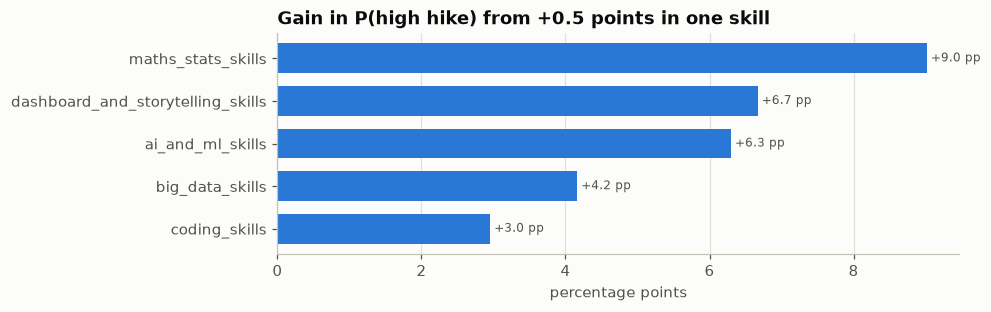

In [18]:
lr_j = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xj, yj)
base_profile = Xj[yj == 0].mean().to_frame().T
p0 = lr_j.predict_proba(base_profile)[0, 1]
uplift = {}
for c in skill_cols:
    prof = base_profile.copy(); prof[c] = min(prof[c].iloc[0] + 0.5, 5)
    uplift[c] = (lr_j.predict_proba(prof)[0, 1] - p0) * 100
uplift = pd.Series(uplift)
print(f'Average low-hike junior: P(high hike) = {p0:.0%}')
hbar(uplift, 'Gain in P(high hike) from +0.5 points in one skill', 'percentage points', fmt='+{:.1f} pp')
plt.show()

**Interpretation.** For a typical low-hike junior, the model's estimated chance of a high hike is about 10%. The chart ranks which +0.5-point improvement raises that chance most.
This is the **prescriptive** output: it tells a junior, or their manager, where training effort pays off first.

## 4. Senior data scientists: which personality traits drive success? (SDS)
### 4.1 Statistical tests

In [19]:
mw_table(sds, trait_cols, 'success_high')

,median_high,median_low,U,p_bonferroni,effect_r,verdict
feature,,,,,,
openness_to_experience,48.0,31.0,5716.5,0.0000,0.7698,significant
conscientiousness,54.0,33.5,5669.0,0.0000,0.7551,significant
extraversion,50.0,34.0,5059.5,0.0000,0.5664,significant
agreeableness,48.0,39.5,4212.5,0.0044,0.3042,significant
neuroticism,35.0,33.0,3451.5,1.0000,0.0686,not significant


McFadden pseudo-R² = 0.757   LLR p-value = 1.52e-34   n = 161


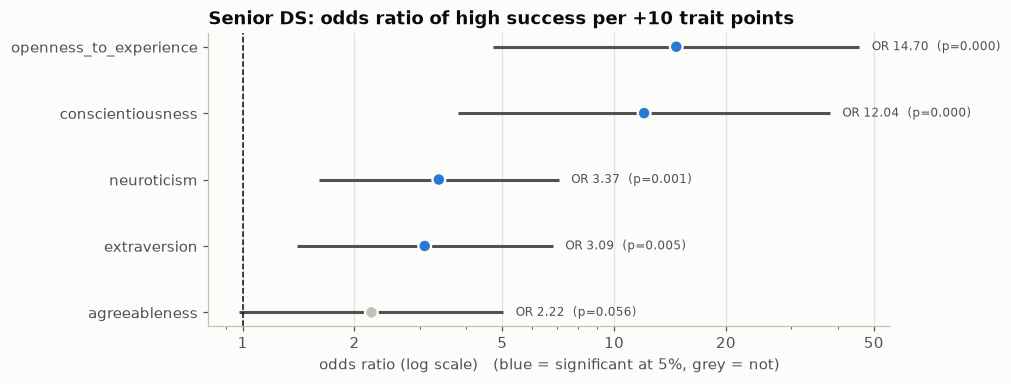

,odds_ratio,ci_low,ci_high,p_value
neuroticism,3.375,1.605,7.097,0.001
extraversion,3.092,1.397,6.844,0.005
openness_to_experience,14.700,4.724,45.746,0.000
agreeableness,2.221,0.980,5.033,0.056
conscientiousness,12.044,3.806,38.114,0.000


In [20]:
# Odds ratio per +10 points on the normalised score (a scale that is easier to read)
sds10 = sds.copy(); sds10[trait_cols] = sds10[trait_cols] / 10
logit_s = smf.logit('success_high ~ ' + ' + '.join(trait_cols), data=sds10).fit(disp=0)
print(f'McFadden pseudo-R² = {logit_s.prsquared:.3f}   LLR p-value = {logit_s.llr_pvalue:.2e}   n = {int(logit_s.nobs)}')
or_s = pd.DataFrame({'odds_ratio': np.exp(logit_s.params), 'ci_low': np.exp(logit_s.conf_int()[0]),
                     'ci_high': np.exp(logit_s.conf_int()[1]), 'p_value': logit_s.pvalues}).drop('Intercept')
forest(or_s, 'Senior DS: odds ratio of high success per +10 trait points', 'odds ratio (log scale)')
plt.show()
or_s.round(3)

**Interpretation.**
- **Openness (r = 0.77) and conscientiousness (r = 0.76) have very large effects.** Extraversion is large (0.57) and agreeableness medium (0.30). **Neuroticism shows no difference on its own** (median 35 vs 33, p = 1.0).
- In the multivariable model, +10 points of **openness multiplies the odds of success by about 15**, and **conscientiousness by about 12**.
- Neuroticism becomes *positive* (OR 3.4) once the other traits are controlled for. This is again a suppression effect, and the confidence intervals are wide because the classes are almost perfectly separable (pseudo-R² = 0.76). **Do not read it as "anxious people succeed"**. The safe conclusion is that neuroticism by itself does not tell successful and unsuccessful seniors apart.

In [21]:
Xs, ys = sds[trait_cols], sds['success_high']
compare_models(Xs, ys)

,accuracy,ROC_AUC,F1
Baseline,0.528 ± 0.006,0.500 ± 0.000,0.691 ± 0.006
Logistic Regression,0.927 ± 0.042,0.964 ± 0.033,0.933 ± 0.037
Decision Tree (depth 3),0.908 ± 0.050,0.940 ± 0.040,0.913 ± 0.051
Random Forest,0.949 ± 0.038,0.996 ± 0.008,0.951 ± 0.039


In [22]:
tree_s = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=RNG).fit(Xs, ys)
print(export_text(tree_s, feature_names=trait_cols, show_weights=True))

|--- openness_to_experience <= 38.50
|   |--- weights: [52.00, 0.00] class: 0
|--- openness_to_experience >  38.50
|   |--- conscientiousness <= 36.50
|   |   |--- weights: [16.00, 0.00] class: 0
|   |--- conscientiousness >  36.50
|   |   |--- agreeableness <= 38.50
|   |   |   |--- weights: [3.00, 2.00] class: 0
|   |   |--- agreeableness >  38.50
|   |   |   |--- weights: [5.00, 83.00] class: 1



**Interpretation.** Personality predicts senior success very well: **Random Forest about 95% accuracy, AUC 0.99**, and logistic regression about 93%. The depth-3 tree gives a three-step screen:
> **Openness > 38.5 → conscientiousness > 36.5 → agreeableness > 38.5** → 83 of 88 people are high-success (94%).
> **Openness ≤ 38.5** → 0 of 52 are high-success.

### 4.2 Personality personas (K-Means clustering)
This step is unsupervised: we cluster seniors on their 5 standardised traits **without** using the success label, then check the success rate in each cluster.
If the personas differ sharply in success, personality profiles are a meaningful lens for HR.

In [23]:
Z = StandardScaler().fit_transform(Xs)
sil = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=RNG).fit_predict(Z)) for k in range(2, 7)}
print('silhouette by k:', {k: round(v, 3) for k, v in sil.items()})
k_best = max(sil, key=sil.get)
k_use = k_best if k_best >= 3 else 3          # at least 3 personas for a richer story
km = KMeans(k_use, n_init=20, random_state=RNG).fit(Z)
sds['persona'] = km.labels_

prof = pd.DataFrame(Z, columns=trait_cols).groupby(sds['persona']).mean()
summary = pd.DataFrame({'size': sds['persona'].value_counts().sort_index(),
                        'success_rate_%': sds.groupby('persona')['success_high'].mean().mul(100).round(0)})
# name each persona by its strongest / weakest traits
def name(row):
    short = lambda c: c.split('_')[0]
    if row['conscientiousness'] > 0.4 and row['openness_to_experience'] > 0.4:
        return 'Conscientious & open'
    if row.mean() < -0.6:
        return 'Low on all traits'
    return f'High {short(row.idxmax())}, low {short(row.idxmin())}'

summary['persona_name'] = prof.apply(name, axis=1)
print(f'k used = {k_use}')
summary.join(prof.round(2))

silhouette by k: {2: 0.313, 3: 0.301, 4: 0.327, 5: 0.212, 6: 0.218}
k used = 4


,size,success_rate_%,persona_name,neuroticism,extraversion,openness_to_experience,agreeableness,conscientiousness
persona,,,,,,,,
0,23,0.0,"High agreeableness, low openness",-0.10,-0.42,-1.19,1.08,-0.91
1,88,89.0,Conscientious & open,-0.22,0.53,0.59,0.33,0.65
2,28,0.0,Low on all traits,-0.48,-0.93,-1.01,-1.28,-0.79
3,22,32.0,"High neuroticism, low agreeableness",1.61,-0.52,0.18,-0.82,-0.63


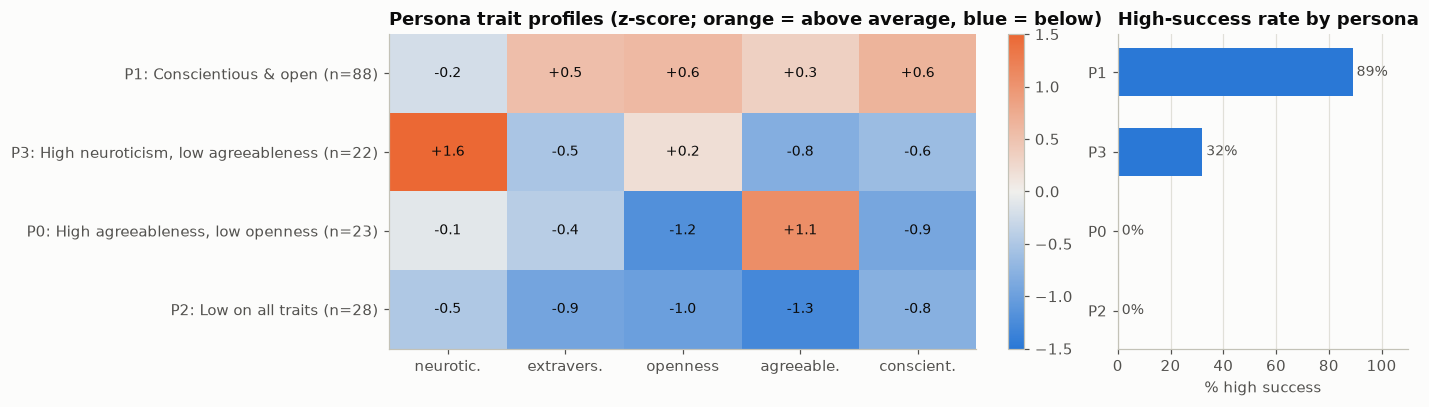

In [24]:
order = summary.sort_values('success_rate_%', ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [2.2, 1]})
ax = axes[0]; ax.grid(False)
P = prof.loc[order]
im = ax.imshow(P.values, cmap=DIV, vmin=-1.5, vmax=1.5, aspect='auto')
for i in range(P.shape[0]):
    for j in range(P.shape[1]):
        ax.text(j, i, f'{P.values[i, j]:+.1f}', ha='center', va='center', fontsize=9, color=INK)
ax.set_xticks(range(5), ['neurotic.', 'extravers.', 'openness', 'agreeable.', 'conscient.'])
ylabels = [f"P{p}: {summary.loc[p, 'persona_name']} (n={summary.loc[p, 'size']})" for p in order]
ax.set_yticks(range(len(order)), ylabels)
ax.set_title('Persona trait profiles (z-score; orange = above average, blue = below)')
plt.colorbar(im, ax=ax, fraction=0.03)
s = summary.loc[order, 'success_rate_%']; s.index = [f'P{p}' for p in order]
axes[1].barh(s.index[::-1], s.values[::-1], color=BLUE, height=0.6); axes[1].grid(axis='y', visible=False)
for i, v in enumerate(s.values[::-1]):
    axes[1].text(v, i, f' {v:.0f}%', va='center', fontsize=9, color=MUTED)
axes[1].set_xlim(0, 110); axes[1].set_title('High-success rate by persona'); axes[1].set_xlabel('% high success')
plt.tight_layout(); plt.show()

**Interpretation.** The clustering never saw the success label, yet it finds personas with very different outcomes:
- **Conscientious & open** (the largest group, n = 88) has an **89% success rate**.
- **High neuroticism, low agreeableness** reaches 32%.
- **High agreeableness, low openness** and **Low on all traits** have **0% success**.

Being agreeable is **not enough** on its own. Without openness and conscientiousness, agreeable seniors do not succeed.

## 5. Synthesis: the career roadmap

In [25]:
def top(s, n=2): return ', '.join(s.index[:n])
roadmap = pd.DataFrame([
    {'stage': '1. Get hired',
     'what_matters_most': f"Experience (+{prem.loc['min_experience','premium_%']:.0f}%/yr), title, skill mix",
     'evidence': f"OLS R²={ols.rsquared:.2f}; Spearman rho={rho:.2f}; band model within-one acc={band_scores.loc[best_name,'within_one_band']:.2f}",
     'action': 'Target Data Scientist / Data Engineer titles; build ML, Spark, algorithms; prefer selective high-pay firms'},
    {'stage': '2. Grow as a junior',
     'what_matters_most': top(or_j['odds_ratio'].sort_values(ascending=False)),
     'evidence': f"Logit pseudo-R²={logit_j.prsquared:.2f}; big-data OR={or_j.loc['big_data_skills','odds_ratio']:.2f} (p={or_j.loc['big_data_skills','p_value']:.2f})",
     'action': 'Invest in storytelling/dashboards and maths-stats, not only tools'},
    {'stage': '3. Succeed as a senior',
     'what_matters_most': top(or_s['odds_ratio'].sort_values(ascending=False)),
     'evidence': f"Logit pseudo-R²={logit_s.prsquared:.2f}; neuroticism OR={or_s.loc['neuroticism','odds_ratio']:.2f} (p={or_s.loc['neuroticism','p_value']:.2f})",
     'action': 'Develop conscientiousness (ownership, delivery) and openness (curiosity); use personas in hiring and coaching'},
]).set_index('stage')
roadmap

,what_matters_most,evidence,action
stage,,,
1. Get hired,"Experience (+12%/yr), title, skill mix",OLS R²=0.58; Spearman rho=0.63; band model within-one ac...,"Target Data Scientist / Data Engineer titles; build ML, ..."
2. Grow as a junior,"maths_stats_skills, dashboard_and_storytelling_skills",Logit pseudo-R²=0.50; big-data OR=2.71 (p=0.01),"Invest in storytelling/dashboards and maths-stats, not o..."
3. Succeed as a senior,"openness_to_experience, conscientiousness",Logit pseudo-R²=0.76; neuroticism OR=3.37 (p=0.00),"Develop conscientiousness (ownership, delivery) and open..."


### Implications for stakeholders
The numbers behind each point are printed in the cells above, and `README.md` summarises the final values.

| Stakeholder | Implication |
|---|---|
| **Students / job seekers** | Experience compounds pay year on year, so internships and early projects matter. Specialised skills (ML, Spark, algorithms, R) are linked to 15 L+ pay, while generic marketing and "communication" keywords are not. Aim for Data Scientist or Data Engineer titles over Data Analyst when possible. |
| **Universities / training providers** | Teach statistics and storytelling/dashboards as core subjects alongside coding. For juniors, these are the strongest drivers of a high hike. Big-data tooling only adds value on top of them. |
| **HR / hiring managers** | Junior hikes are predictable from skills (AUC 0.90). Use the transparent storytelling + maths rule to make hike decisions explainable. For senior, customer-facing roles, screen for openness and conscientiousness (AUC up to 0.99) and use the personas for coaching. |
| **Companies** | The top-10 volume hirers pay about 11% less at the same title and experience, and they provide two-thirds of openings. Selective firms win talent on pay. Volume hirers can compete through faster title progression, since a Senior title alone adds about 14–36% even at the same experience. |

### Limitations
- Analytics Jobs salary is banded, its text is truncated, and the file is not limited to data roles. The band model is therefore approximate. Within-one-band accuracy is the fairer metric.
- DataScience Jobs reports company-level averages, not individuals.
- JDS (139 rows) and SDS (161 rows) are small samples from one company. They show association, not causation, and need validation on more data.
- Logistic odds ratios for SDS have wide confidence intervals because the classes are almost separable. Rely on direction and ranking, not exact values.
- The datasets cannot be joined at person level. The roadmap links them conceptually, by career stage.